# 프로젝트 8-1. Stable Diffusion 실습

- 실습: Stable Diffusion으로 문장에서 그림을 만들고(Text-to-Image), 마스크 부분만 다시 그린다(Inpainting).
- 실행 환경: Google Colab A100 GPU

In [ ]:
# @title 실행 준비: 패키지 설치
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y', '-q', 'torchao'])
_ = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'diffusers==0.41.0', 'accelerate'], check=True)

In [ ]:
# !pip install diffusers transformers accelerate torch torchvision

In [ ]:
import diffusers
import transformers

diffusers.__version__

'0.41.0'

In [ ]:
transformers.__version__

'5.18.0'

In [ ]:
# !pip install diffusers==0.33.1
# !pip install transformers==4.52.4

In [ ]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [ ]:
from diffusers import StableDiffusionPipeline, StableDiffusionInpaintPipeline
from PIL import Image
import matplotlib.pyplot as plt

def display_image(image):
    plt.imshow(image)
    plt.axis('off')
    plt.show()

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Text-to-Image pipeline loaded.
Generating image for prompt: 'A photo of man riding a horse in the moon wearing astronaut outfits'


  0%|          | 0/30 [00:00<?, ?it/s]

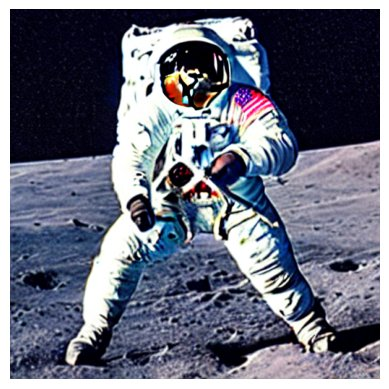

Image saved as generated_defect_0.png


In [ ]:
# --- 1.1 파이프라인 로드 ---
model_id_text2img = "runwayml/stable-diffusion-v1-5"
pipe_text2img = StableDiffusionPipeline.from_pretrained(model_id_text2img, torch_dtype=torch.float16)
pipe_text2img = pipe_text2img.to(device)
print("Text-to-Image pipeline loaded.")

# --- 1.2 프롬프트 정의 및 이미지 생성 ---
prompt_defect = "A photo of man riding a horse in the moon wearing astronaut outfits"
negative_prompt = "blurry, deformed, cartoon, painting, illustration, normal, no defect"

# 파라미터 설정
num_steps = 30
guidance_scale_val = 8.5
num_images_per_prompt = 1 # 한 번에 여러 개 생성 가능

print(f"Generating image for prompt: '{prompt_defect}'")
# seed 고정으로 재현성 확보 (선택 사항)
generator = torch.Generator(device=device).manual_seed(42)

with torch.autocast("cuda"): # float16 연산 시
    generated_images = pipe_text2img(
        prompt_defect,
        negative_prompt=negative_prompt,
        num_inference_steps=num_steps,
        guidance_scale=guidance_scale_val,
        num_images_per_prompt=num_images_per_prompt,
        # generator=generator
    ).images

# --- 1.3 결과 확인 및 저장 ---
for i, image in enumerate(generated_images):
    display_image(image)
    try:
        image.save(f"generated_defect_{i}.png")
        print(f"Image saved as generated_defect_{i}.png")
    except Exception as e:
        print(f"Error saving image: {e}")


**📝 이론 정리 / 기능 묘사 / 코멘트**

- 이론 정리: Stable Diffusion은 이미지에 노이즈를 더하는 순방향 과정과 노이즈를 걷어 내는 역방향 과정을 학습한 확산 모델로, 픽셀이 아닌 latent space에서 U-Net이 노이즈를 제거하고 텍스트 내용에 맞는 그림을 만든다. num_inference_steps가 많을수록 품질이 높지만 오래 걸리고, guidance_scale이 높을수록 프롬프트를 충실히 따른다.
- 기능 묘사: diffusers로 SD 1.5를 float16으로 불러와 "달에서 말을 탄 우주인" 문장으로 30단계, guidance 8.5로 그림을 만들었다.
- 코멘트: 실제 말을 탄 우주인이 나오는 줄 알았는데 원래 예전 실행에서는 말을 탔었는데 이번 실행에는 말 없이 우주인만 나와서 놀랐다.

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Inpainting pipeline loaded.
Using placeholder initial image and mask.


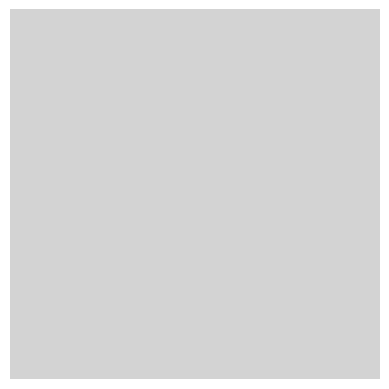

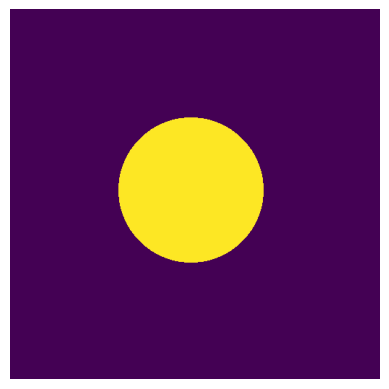

Inpainting with prompt: 'A deep circular dent with rough edges'


  0%|          | 0/50 [00:00<?, ?it/s]

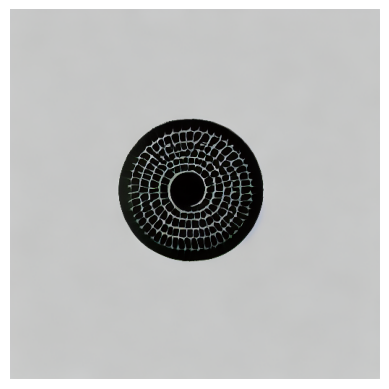

Image saved as inpainted_defect_0.png


In [ ]:
# --- 2.1 파이프라인 로드 ---
# Inpainting 전용 모델 사용
model_id_inpaint = "stable-diffusion-v1-5/stable-diffusion-inpainting" # 또는 다른 inpainting 모델
try:
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(model_id_inpaint, torch_dtype=torch.float16, variant="fp16")
    pipe_inpaint = pipe_inpaint.to(device)
    print("Inpainting pipeline loaded.")
except Exception as e:
    print(f"Could not load inpainting pipeline: {e}. Skipping inpainting part or use a general pipeline.")
    pipe_inpaint = None # 예외 처리

if pipe_inpaint:
    # --- 2.2 원본 이미지 및 마스크 준비 ---
    init_image = Image.new("RGB", (512, 512), "lightgray") # 밝은 회색 배경
    mask_image = Image.new("L", (512, 512), "black")
    from PIL import ImageDraw
    draw = ImageDraw.Draw(mask_image)
    draw.ellipse(((150, 150), (350, 350)), fill="white") # 중앙 흰색 원형 마스크
    print("Using placeholder initial image and mask.")
    display_image(init_image)
    display_image(mask_image)


    # --- 2.3 프롬프트 정의 및 이미지 생성 ---
    prompt_inpaint_defect = "A deep circular dent with rough edges"
    negative_prompt_inpaint = "smooth, perfect, flat, no dent, blurry"

    print(f"Inpainting with prompt: '{prompt_inpaint_defect}'")
    with torch.autocast("cuda"):
        inpainted_images = pipe_inpaint(
            prompt=prompt_inpaint_defect,
            image=init_image,
            mask_image=mask_image,
            negative_prompt=negative_prompt_inpaint,
            num_inference_steps=50, # Inpainting은 조금 더 많은 step이 필요할 수 있음
            guidance_scale=7.5
        ).images

    # --- 2.4 결과 확인 및 저장 ---
    for i, image in enumerate(inpainted_images):
        display_image(image)
        try:
            image.save(f"inpainted_defect_{i}.png")
            print(f"Image saved as inpainted_defect_{i}.png")
        except Exception as e:
            print(f"Error saving image: {e}")

# TODO: 다양한 원본 이미지, 마스크, 프롬프트로 실험해보세요!
#       예: 실제 정상 제품 이미지에 사용자가 직접 그린 마스크 적용

Using device: cuda


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Inpainting pipeline loaded with stable-diffusion-v1-5/stable-diffusion-inpainting.
Image loaded and resized to 512x512.


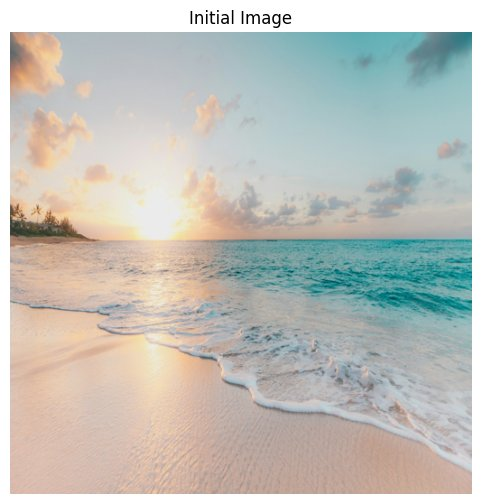

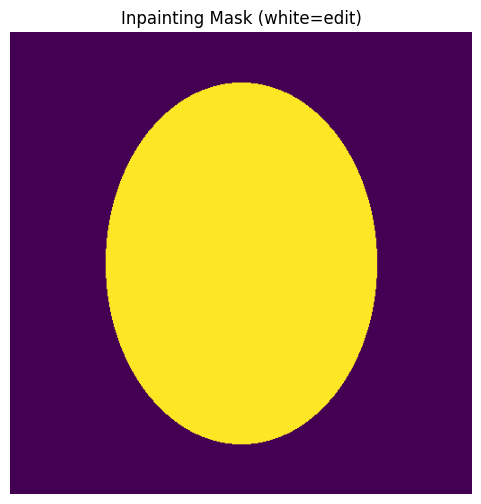

Running inpainting with prompt: A treasure chest buried in the sand


  0%|          | 0/50 [00:00<?, ?it/s]

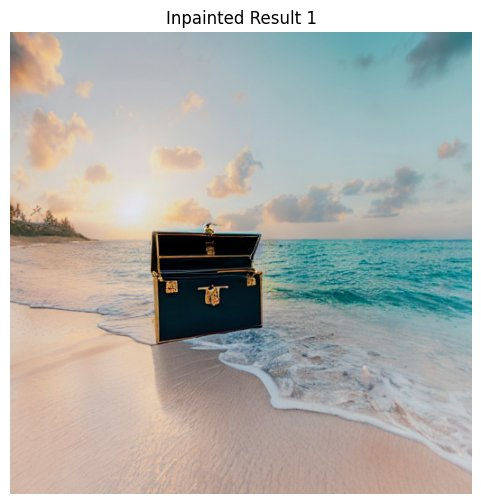

Saved: result_inpainted_0.png


In [ ]:
import torch
from diffusers import StableDiffusionInpaintPipeline
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import requests
from io import BytesIO

# --- 1. 디바이스 설정 ---
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# --- 2. 이미지 시각화 함수 ---
def display_image(image, title="Generated Image"):
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(title)
    plt.axis('off')
    plt.show()

# --- 3. 파이프라인 로딩 ---
model_id_inpaint = "stable-diffusion-v1-5/stable-diffusion-inpainting"
try:
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
        model_id_inpaint,
        torch_dtype=torch.float16 if device == "cuda" else torch.float32,
        variant="fp16"
    )
    pipe_inpaint = pipe_inpaint.to(device)
    print(f"Inpainting pipeline loaded with {model_id_inpaint}.")
except Exception as e:
    print(f"Could not load inpainting pipeline: {e}")
    pipe_inpaint = None

# --- 4. 이미지와 마스크 준비 ---
if pipe_inpaint:
    # 이미지 로드
    image_url = "https://images.unsplash.com/photo-1507525428034-b723cf961d3e?q=80&w=2070&auto=format&fit=crop"
    try:
        response = requests.get(image_url)
        response.raise_for_status()
        init_image = Image.open(BytesIO(response.content)).convert("RGB").resize((512, 512))
        print("Image loaded and resized to 512x512.")
    except Exception as e:
        print(f"Image load failed: {e}. Using placeholder image.")
        init_image = Image.new("RGB", (512, 512))
        draw = ImageDraw.Draw(init_image)
        draw.rectangle([0, 0, 512, 280], fill="skyblue")
        draw.rectangle([0, 280, 512, 512], fill="goldenrod")
        draw.ellipse([400, 60, 440, 100], fill="gold")

    # 마스크 생성 (중앙 타원형)
    mask_image = Image.new("L", (512, 512), 0)  # 검정 배경
    draw = ImageDraw.Draw(mask_image)
    ellipse_box = [106, 56, 406, 456]  # 대략 중앙 타원 (너비 300, 높이 400)
    draw.ellipse(ellipse_box, fill=255)  # 흰색 영역을 인페인팅할 영역으로

    # 이미지 확인
    display_image(init_image, "Initial Image")
    display_image(mask_image, "Inpainting Mask (white=edit)")

    # --- 5. 프롬프트 정의 ---
    prompt = "A treasure chest buried in the sand"
    negative_prompt = "blurry, deformed, cartoon, illustration, watermark, text, signature, extra limbs"

    print(f"Running inpainting with prompt: {prompt}")

    generator = torch.Generator(device=device).manual_seed(1234)

    # --- 6. 인페인팅 수행 ---
    if device == "cuda":
        with torch.autocast("cuda"):
            result = pipe_inpaint(
                prompt=prompt,
                image=init_image,
                mask_image=mask_image,
                negative_prompt=negative_prompt,
                guidance_scale=8.5,
                num_inference_steps=50,
                generator=generator
            )
    else:
        result = pipe_inpaint(
            prompt=prompt,
            image=init_image,
            mask_image=mask_image,
            negative_prompt=negative_prompt,
            guidance_scale=8.5,
            num_inference_steps=50,
            generator=generator
        )

    # --- 7. 결과 출력 및 저장 ---
    if result and result.images:
        for i, out_img in enumerate(result.images):
            display_image(out_img, f"Inpainted Result {i+1}")
            out_img.save(f"result_inpainted_{i}.png")
            print(f"Saved: result_inpainted_{i}.png")
    else:
        print("No images returned from inpainting.")

else:
    print("Pipeline not loaded. Cannot run inpainting.")


**📝 이론 정리 / 기능 묘사 / 코멘트**

- 이론 정리: Inpainting은 원본 이미지와 마스크를 입력받아, 마스크된 영역만 프롬프트에 따라 새로 생성한다.
- 기능 묘사: 스테이블 디퓨전 Inpainting으로 회색 판의 원 안에는 찌그러짐을, 해변 사진의 타원 안에는 보물 상자를 그렸다.
- 코멘트: 실제로 저 마스킹 된 부분만 수정하는 기능은 제미나이나 GPT의 이미지 수정 기능에도 있었는데 원래 요런 기능이었다는 것을 알게 되었다.

# 추가 실험: 최신 이미지 모델과 비교

위 실습의 SD 1.5 예시 3개를 같은 프롬프트·입력 이미지·마스크로 FLUX.2 [klein]에 다시 그려 비교한다. SD 결과는 위 셀이 저장한 이미지를 그대로 쓴다.

- Test 1: SD 1.5와 FLUX.2 [klein]은 프롬프트를 얼마나 따르고, 인페인팅에서 마스크 밖을 얼마나 그대로 두는가?
- Test 2: FLUX.2 [klein]의 빠른 버전(distilled)과 원본(base)은 시간과 결과가 얼마나 다른가?

| 항목 | 설정 |
|---|---|
| 예시 | ① 달에서 말을 탄 우주인 (Text-to-Image) ② 회색 판의 원형 찌그러짐 (Inpainting) ③ 해변의 보물 상자 (Inpainting) |
| 모델 | FLUX.2 [klein] 4B distilled (4단계, guidance 1.0), FLUX.2 [klein] 4B base (50단계, guidance 4.0). 네거티브 프롬프트 없음 |
| 해상도·시드 | 512×512 (위 예시와 같음), 시드 0, 예시마다 1장 |
| 기록 | 장당 시간, 최대 GPU 메모리, 인페인팅은 마스크 밖 픽셀값의 평균 변화 (0~255) |

In [ ]:
# @title 추가 실험 도구: FLUX.2 [klein] 불러오기와 측정
import gc, time, textwrap
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
from huggingface_hub import snapshot_download
from diffusers import Flux2KleinPipeline, Flux2KleinInpaintPipeline, Flux2Transformer2DModel, FlowMatchEulerDiscreteScheduler

# 위 SD 파이프라인이 쓰던 GPU 메모리를 비운다
for _name in ['pipe_text2img', 'pipe_inpaint']:
    globals().pop(_name, None)
gc.collect()
torch.cuda.empty_cache()

FLUX = {'distilled': dict(repo='black-forest-labs/FLUX.2-klein-4B', steps=4, guidance=1.0),
        'base': dict(repo='black-forest-labs/FLUX.2-klein-base-4B', steps=50, guidance=4.0)}
PARTS = ['model_index.json', 'scheduler/*', 'text_encoder/*', 'tokenizer/*', 'transformer/*', 'vae/*']

# 위 예시와 같은 입력 (회색 판과 원형 마스크는 위 셀과 같은 코드로 다시 만든다)
gray_image = Image.new('RGB', (512, 512), 'lightgray')
circle_mask = Image.new('L', (512, 512), 'black')
ImageDraw.Draw(circle_mask).ellipse(((150, 150), (350, 350)), fill='white')
TASKS = {
    'text-to-image': dict(prompt=prompt_defect, sd_file='generated_defect_0.png'),
    'inpainting: dent': dict(prompt=prompt_inpaint_defect, image=gray_image, mask=circle_mask, sd_file='inpainted_defect_0.png'),
    'inpainting: chest': dict(prompt=prompt, image=init_image, mask=mask_image, sd_file='result_inpainted_0.png'),
}


def outside_change(out, image, mask):
    '''마스크 밖(검은 부분) 픽셀값의 평균 절대 변화 (0~255)'''
    a = np.asarray(out.convert('RGB').resize(image.size), dtype=np.float32)
    b = np.asarray(image.convert('RGB'), dtype=np.float32)
    keep = np.asarray(mask.convert('L')) < 128
    return float(np.abs(a - b)[keep].mean())


SHARED = {}  # text_encoder·tokenizer·vae는 두 모델이 같은 파일이라 한 번만 불러 같이 쓴다


def load_flux(variant):
    '''텍스트→이미지·인페인팅 파이프라인. 두 번째 모델부터는 transformer와 scheduler만 새로 불러온다'''
    path = snapshot_download(FLUX[variant]['repo'],
                             allow_patterns=['model_index.json', 'scheduler/*', 'transformer/*'] if SHARED else PARTS)
    if not SHARED:
        full = Flux2KleinInpaintPipeline.from_pretrained(path, torch_dtype=torch.bfloat16).to('cuda')
        SHARED.update(vae=full.vae, text_encoder=full.text_encoder, tokenizer=full.tokenizer)
        transformer, scheduler = full.transformer, full.scheduler
        del full
    else:
        transformer = Flux2Transformer2DModel.from_pretrained(path, subfolder='transformer', torch_dtype=torch.bfloat16).to('cuda')
        scheduler = FlowMatchEulerDiscreteScheduler.from_pretrained(path, subfolder='scheduler')
    parts = dict(SHARED, transformer=transformer, scheduler=scheduler, is_distilled=(variant == 'distilled'))
    pipes = Flux2KleinPipeline(**parts), Flux2KleinInpaintPipeline(**parts)
    for p in pipes:
        p.set_progress_bar_config(disable=True)
    return pipes


def run_flux(variant):
    '''예시 3개를 시드 0으로 한 장씩 그리고 시간·최대 GPU 메모리·마스크 밖 변화를 기록한다'''
    cfg = FLUX[variant]
    text2img, inpaint = load_flux(variant)
    # 첫 실행의 준비 시간이 측정에 섞이지 않게 1단계씩 미리 돌린다
    text2img(prompt='warm-up', height=512, width=512, num_inference_steps=1, guidance_scale=cfg['guidance'])
    inpaint(prompt='warm-up', image=gray_image, mask_image=circle_mask, strength=1.0,
            num_inference_steps=1, guidance_scale=cfg['guidance'])
    rows, images = [], {}
    for name, task in TASKS.items():
        gen = torch.Generator('cuda').manual_seed(0)
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
        t0 = time.time()
        if 'image' in task:
            out = inpaint(prompt=task['prompt'], image=task['image'], mask_image=task['mask'], strength=1.0,
                          num_inference_steps=cfg['steps'], guidance_scale=cfg['guidance'], generator=gen).images[0]
        else:
            out = text2img(prompt=task['prompt'], height=512, width=512,
                           num_inference_steps=cfg['steps'], guidance_scale=cfg['guidance'], generator=gen).images[0]
        torch.cuda.synchronize()
        rows.append(dict(model=f'FLUX.2 klein {variant}', example=name, seconds=round(time.time() - t0, 1),
                         peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 2**30, 1),
                         outside_change=round(outside_change(out, task['image'], task['mask']), 2) if 'image' in task else None))
        images[name] = out
        out.save(f"flux_{variant}_{name.split(': ')[-1].replace('-', '')}.png")
    del text2img, inpaint
    gc.collect()
    torch.cuda.empty_cache()
    return rows, images


In [ ]:
# @title Test 1·2 실행: FLUX.2 [klein] distilled·base로 예시 3개 그리기
ROWS, FLUX_IMAGES = [], {}
for variant in ['distilled', 'base']:
    rows, images = run_flux(variant)
    ROWS += rows
    FLUX_IMAGES[variant] = images
for name, task in TASKS.items():
    if 'image' in task:
        sd = Image.open(task['sd_file'])
        ROWS.append(dict(model='SD 1.5 (위 실습)', example=name, seconds=None, peak_gpu_gb=None,
                         outside_change=round(outside_change(sd, task['image'], task['mask']), 2)))
RESULT = pd.DataFrame(ROWS)
print(RESULT.to_string(index=False))


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

                 model           example  seconds  peak_gpu_gb  outside_change
FLUX.2 klein distilled     text-to-image      0.4         15.5             NaN
FLUX.2 klein distilled  inpainting: dent      0.6         15.5            2.29
FLUX.2 klein distilled inpainting: chest      0.6         15.5            3.95
     FLUX.2 klein base     text-to-image      6.4         15.5             NaN
     FLUX.2 klein base  inpainting: dent     11.2         15.5            2.57
     FLUX.2 klein base inpainting: chest     11.3         15.5            4.70
         SD 1.5 (위 실습)  inpainting: dent      NaN          NaN           12.37
         SD 1.5 (위 실습) inpainting: chest      NaN          NaN            7.49


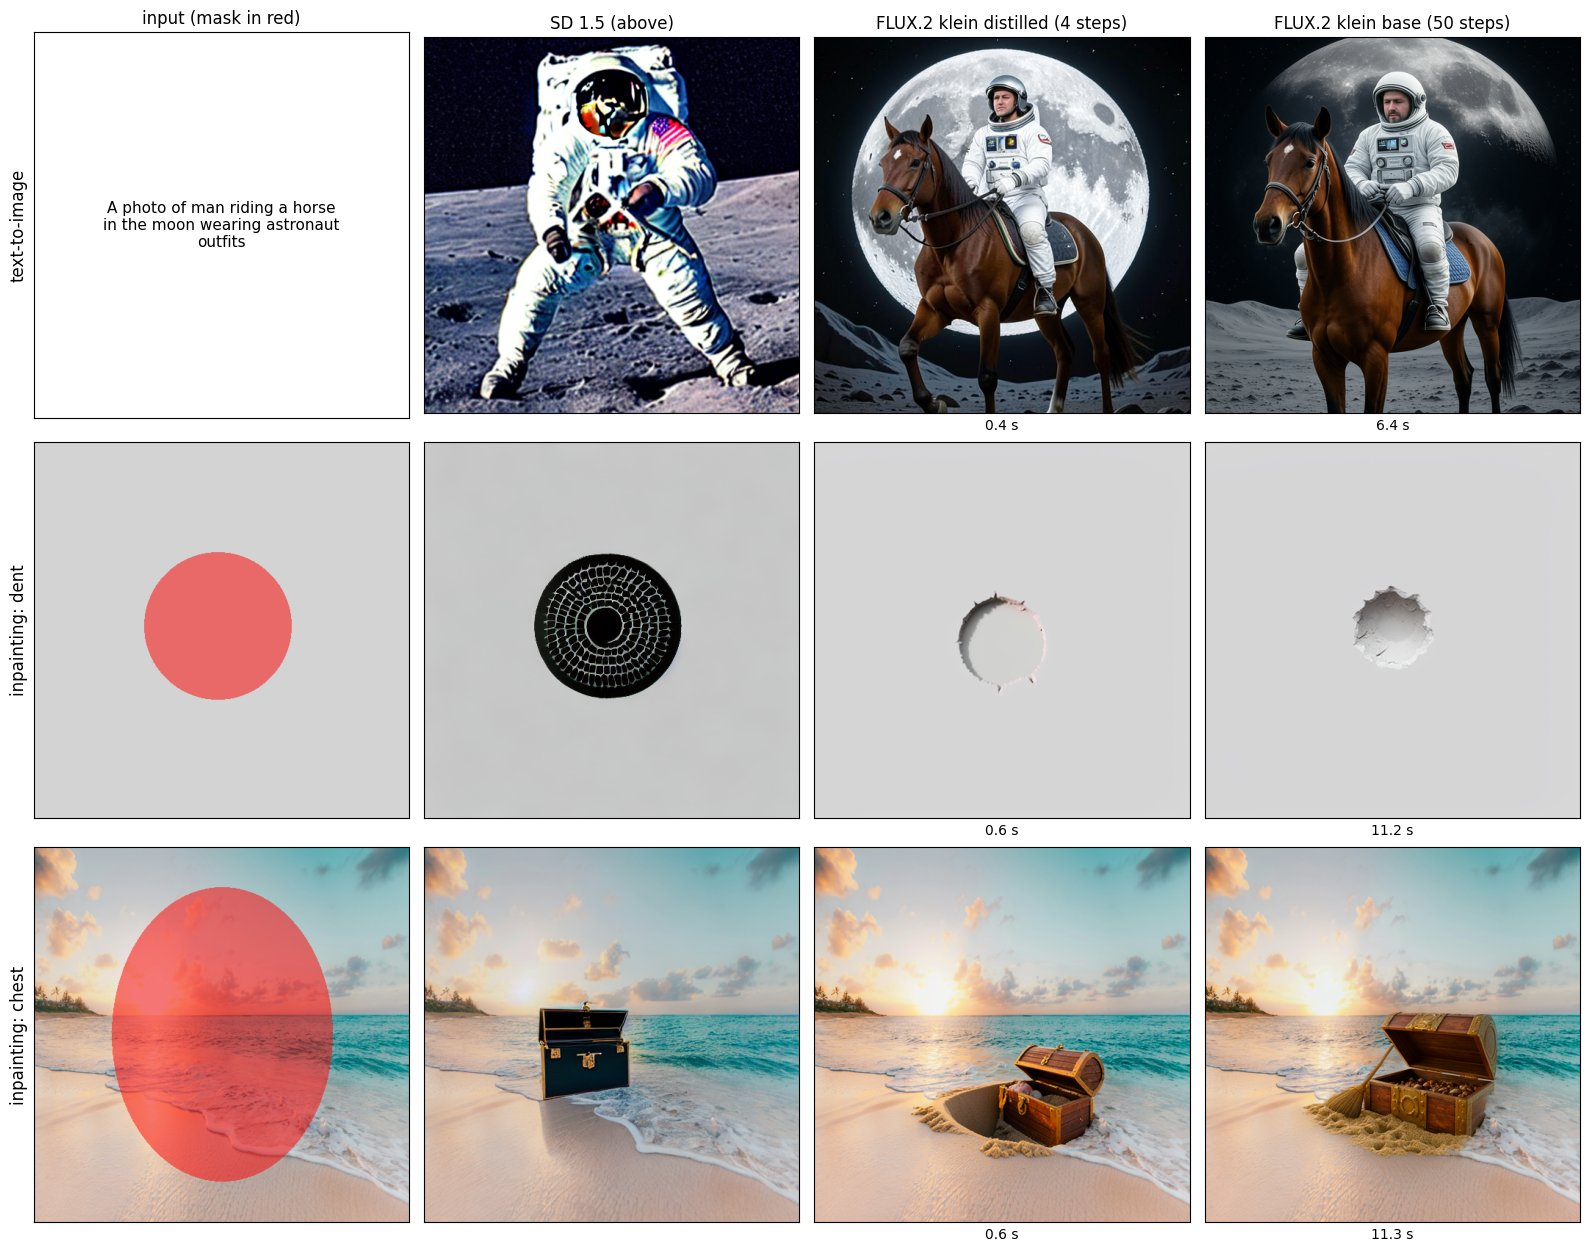

In [ ]:
# @title 그림 1. 같은 프롬프트·입력으로 그린 결과 (왼쪽부터 입력, SD 1.5, FLUX.2 klein distilled, base)
sec = {(r['model'], r['example']): r['seconds'] for r in ROWS}
cols = ['input (mask in red)', 'SD 1.5 (above)', 'FLUX.2 klein distilled (4 steps)', 'FLUX.2 klein base (50 steps)']
fig, axes = plt.subplots(len(TASKS), 4, figsize=(16, 4.2 * len(TASKS)))
for i, (name, task) in enumerate(TASKS.items()):
    if 'image' in task:
        view = np.asarray(task['image'].convert('RGB'), dtype=np.float32) / 255
        m = np.asarray(task['mask'].convert('L')) >= 128
        view[m] = view[m] * 0.5 + np.array([1.0, 0.0, 0.0]) * 0.5
        axes[i, 0].imshow(view)
    else:
        axes[i, 0].text(0.5, 0.5, '\n'.join(textwrap.wrap(task['prompt'], 30)), ha='center', va='center', fontsize=11)
    axes[i, 1].imshow(Image.open(task['sd_file']))
    for j, variant in enumerate(['distilled', 'base'], start=2):
        axes[i, j].imshow(FLUX_IMAGES[variant][name])
        axes[i, j].set_xlabel(f"{sec[(f'FLUX.2 klein {variant}', name)]} s")
    axes[i, 0].set_ylabel(name, fontsize=12)
    for j in range(4):
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        if i == 0:
            axes[i, j].set_title(cols[j])
plt.tight_layout()
plt.show()


### Test 1 정리

- 실험 내용: 실습에서 사용한 스테이블 디퓨전 모델은 오래되어 이미지가 깨지기도 해서, 비교적 최신 이미지 모델인 FLUX.2로 위 실습과 같은 내용을 그려 보고 위의 원래 결과와 비교해 보았다.
- 결과: SD는 말을 그렸다 안그렸다 품질도 낮게 나오지만, FLUX는 말을 탄 우주인을 그렸고, 찌그러짐과 보물 상자도 FLUX 쪽이 문장대로 나왔다. 인페인팅에서 마스크 밖 평균 변화도 FLUX가 스테이블 디퓨전 모델보다 작았다.
- 분석: 일단 비교해보았을때는 FLUX 쪽이 좀 더 프롬프팅을 잘 따르고 깨끗한 듯 하지만, 각자 개성이 있어 비교하기는 쉽지 않을 것 같다

### Test 2 정리

- 실험 내용: FLUX.2에는 4단계로 그리는 빠른 버전(distilled)과 50단계로 그리는 원본(base)이 있어서, 같은 예시로 시간과 결과를 비교해 보았다.
- 결과: distilled는 장당 0.4~0.6초, base는 6.4~11.3초로 distilled가 16~19배 빨랐고, 그림은 둘 다 문장대로 나왔다.
- 분석: 확실히 50단계로 했을 때가 꽤 사실적으로 나오지만, 대신시간이 거의 10~20배 이상은 들어서 오래 걸렸다